In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../data/insurance.csv")

In [3]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [4]:
df.shape

(1338, 7)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [6]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [7]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(1)

In [10]:
df[df.duplicated(keep=False)]

,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


In [11]:
df = df.drop_duplicates()

In [13]:
df.shape

(1337, 7)

In [14]:
df["sex"].unique()

<StringArray>
['female', 'male']
Length: 2, dtype: str

In [15]:
df["smoker"].unique()

<StringArray>
['yes', 'no']
Length: 2, dtype: str

In [16]:
df["region"].unique()

<StringArray>
['southwest', 'southeast', 'northwest', 'northeast']
Length: 4, dtype: str

In [17]:
df["sex"].value_counts()

sex
male      675
female    662
Name: count, dtype: int64

In [18]:
df["smoker"].value_counts()

smoker
no     1063
yes     274
Name: count, dtype: int64

In [19]:
df["region"].value_counts()

region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64

In [20]:
numerical_columns = df.select_dtypes(include=["int64", "float64"]).columns

numerical_columns

Index(['age', 'bmi', 'children', 'charges'], dtype='str')

In [21]:
X = df.drop("charges", axis=1)
y = df["charges"]

In [22]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (1337, 6)
Target shape: (1337,)


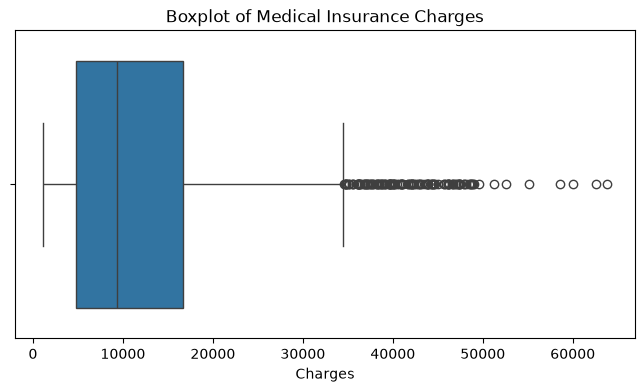

In [23]:
plt.figure(figsize=(8, 4))

sns.boxplot(x=df["charges"])

plt.title("Boxplot of Medical Insurance Charges")
plt.xlabel("Charges")

plt.show()

In [24]:
Q1 = df["charges"].quantile(0.25)
Q3 = df["charges"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df["charges"] < lower_bound) |
    (df["charges"] > upper_bound)
]

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of Outliers:", len(outliers))

Lower Bound: -13120.716174999998
Upper Bound: 34524.777625
Number of Outliers: 139


In [25]:
outliers.sort_values(
    by="charges",
    ascending=False
).head(10)

,age,sex,bmi,children,smoker,region,charges
543,54,female,47.410,0,yes,southeast,63770.42801
1300,45,male,30.360,0,yes,southeast,62592.87309
1230,52,male,34.485,3,yes,northwest,60021.39897
577,31,female,38.095,1,yes,northeast,58571.07448
819,33,female,35.530,0,yes,northwest,55135.40209
1146,60,male,32.800,0,yes,southwest,52590.82939
34,28,male,36.400,1,yes,southwest,51194.55914
1241,64,male,36.960,2,yes,southeast,49577.66240
1062,59,male,41.140,1,yes,southeast,48970.24760
488,44,female,38.060,0,yes,southeast,48885.13561


In [26]:
df.groupby("smoker")["charges"].mean()

smoker
no      8440.660307
yes    32050.231832
Name: charges, dtype: float64

In [27]:
smoker_avg = df.groupby("smoker")["charges"].mean()

percentage_difference = (
    (smoker_avg["yes"] - smoker_avg["no"]) / smoker_avg["no"]
) * 100

print(f"Percentage Difference: {percentage_difference:.2f}%")

Percentage Difference: 279.71%


In [28]:
df["bmi_category"] = pd.cut(
    df["bmi"],
    bins=[0, 18.5, 25, 30, 100],
    labels=["Underweight", "Normal", "Overweight", "Obese"]
)

In [29]:
df["bmi_category"].value_counts()

bmi_category
Obese          704
Overweight     386
Normal         226
Underweight     21
Name: count, dtype: int64

In [30]:
bmi_charges = df.groupby("bmi_category", observed=True)["charges"].mean()

print(bmi_charges)

bmi_category
Underweight     8657.620652
Normal         10435.440719
Overweight     10997.803881
Obese          15580.700985
Name: charges, dtype: float64


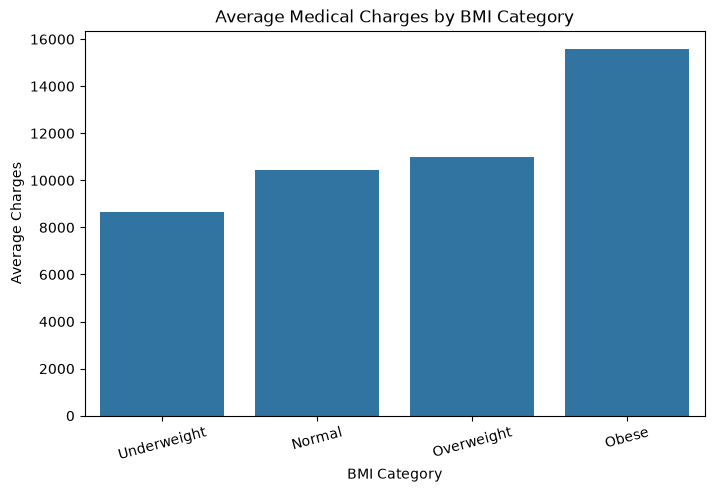

In [31]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="bmi_category",
    y="charges",
    order=["Underweight", "Normal", "Overweight", "Obese"],
    errorbar=None
)

plt.title("Average Medical Charges by BMI Category")
plt.xlabel("BMI Category")
plt.ylabel("Average Charges")
plt.xticks(rotation=15)

plt.show()